## Introducción General del Proyecto
Este proyecto de Machine Learning aborda la problemática ambiental del Valle de Aburrá centrándose en la **predicción del Índice de Calidad del Aire (ICA)** para el día siguiente ($t+1$).

A través del análisis de datos de partículas contaminantes (PM2.5) y variables meteorológicas (lluvia, viento y temperatura), se implementa un pipeline completo que incluye:
1. Carga y exploración visual de datos (EDA).
2. Ingeniería de características (creación de retardos temporales, estadísticas móviles y variables críticas estacionales).
3. Entrenamiento y evaluación comparativa de múltiples modelos de clasificación clásicos.
4. Optimización final mediante validación cruzada respetando la secuencia temporal (`TimeSeriesSplit`).

# Evaluación y Predicción de Calidad del Aire (PM2.5) en el Valle de Aburrá
Este cuaderno de Jupyter tiene como objetivo analizar los datos históricos de contaminación por material particulado (PM2.5) y variables meteorológicas en el Valle de Aburrá. A través del aprendizaje automático (Machine Learning), se desarrolla y evalúa un modelo predictivo basado en **Random Forest** para clasificar la categoría del Índice de Calidad del Aire (ICA) del día siguiente.

## Celda 1: Importación de Librerías
En esta sección se importan las herramientas y librerías fundamentales de Python necesarias para la manipulación de datos (`pandas`, `numpy`), visualización (`matplotlib`, `seaborn`) y los algoritmos de aprendizaje automático y métricas de evaluación (`scikit-learn`).

In [1]:
# ==============================================================================
# Celda 1: Importación de librerías necesarias
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import recall_score

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


## Celda 2: Exploración Inicial de Datos (EDA) y Visualización
En esta celda se cargan los archivos CSV con datos de calidad del aire (`pm25_diario.csv`) y variables meteorológicas (`meteo_diario.csv`). Se realiza una inspección general de la estructura de los datos, el recuento de registros por categoría ICA y se generan gráficos para visualizar la distribución del PM2.5 y su evolución temporal.

--- Información general de PM2.5 ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27553 entries, 0 to 27552
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   estacion   27553 non-null  object 
 1   dia        27553 non-null  object 
 2   pm25       27553 non-null  float64
 3   horas      27553 non-null  int64  
 4   ica        27553 non-null  object 
 5   clase      27553 non-null  int64  
 6   municipio  27553 non-null  object 
 7   latitud    27553 non-null  float64
 8   longitud   27553 non-null  float64
dtypes: float64(3), int64(2), object(4)
memory usage: 1.9+ MB
None

--- Conteo de registros por categoría ICA ---
ica
Aceptable           20124
Buena                6939
Dañina sensibles      388
Dañina                102
Name: count, dtype: int64


/tmp/ipykernel_1903/4026591739.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_pm_raw, x='ica', y='pm25', palette='Set2')


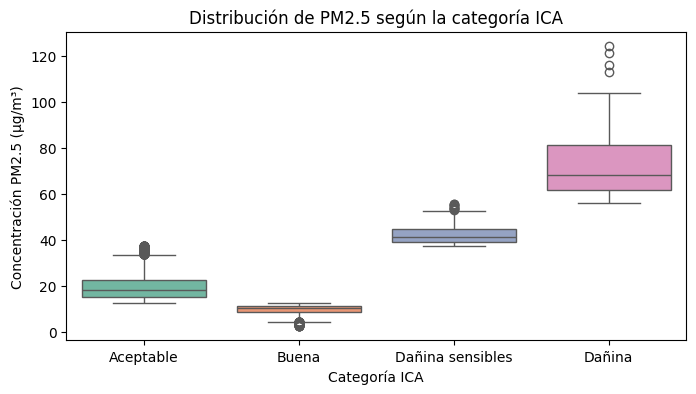

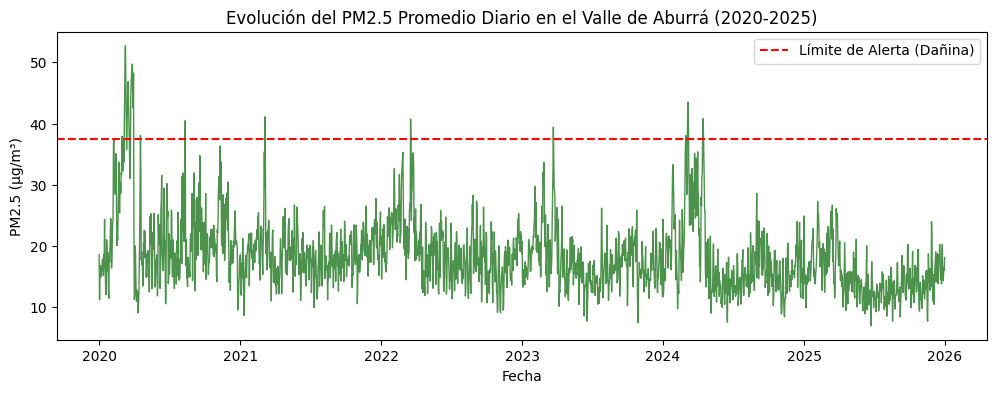

In [2]:
# ==============================================================================
# Celda 2: Exploración inicial de los datos (EDA)
# ==============================================================================
# Cargar archivos CSV subidos a Colab
df_pm_raw = pd.read_csv('pm25_diario.csv')
df_met_raw = pd.read_csv('meteo_diario.csv')

print("--- Información general de PM2.5 ---")
print(df_pm_raw.info())
print("\n--- Conteo de registros por categoría ICA ---")
print(df_pm_raw['ica'].value_counts())

# Gráfico 1: Distribución de PM2.5 por categoría ICA
plt.figure(figsize=(8, 4))
sns.boxplot(data=df_pm_raw, x='ica', y='pm25', palette='Set2')
plt.title('Distribución de PM2.5 según la categoría ICA')
plt.xlabel('Categoría ICA')
plt.ylabel('Concentración PM2.5 (µg/m³)')
plt.show()

# Gráfico 2: Serie de tiempo del PM2.5 promedio diario
df_pm_raw['dia'] = pd.to_datetime(df_pm_raw['dia'])
df_daily_ts = df_pm_raw.groupby('dia')['pm25'].mean()

plt.figure(figsize=(12, 4))
plt.plot(df_daily_ts.index, df_daily_ts.values, color='darkgreen', alpha=0.7, linewidth=1)
plt.axhline(y=37.5, color='red', linestyle='--', label='Límite de Alerta (Dañina)')
plt.title('Evolución del PM2.5 Promedio Diario en el Valle de Aburrá (2020-2025)')
plt.xlabel('Fecha')
plt.ylabel('PM2.5 (µg/m³)')
plt.legend()
plt.show()

## Celda 3: Preprocesamiento e Ingeniería de Características
Aquí se unifican las bases de datos mediante una agregación diaria. Se realiza la imputación de valores faltantes y se construyen variables predictivas clave, tales como:
- **Lags (Rezagos):** Valores de PM2.5 de días anteriores (1 a 3 días).
- **Estadísticas móviles:** Promedios y máximos acumulados de 3 días.
- **Variables temporales:** Indicadores de fin de semana y períodos de temporada crítica.
- **Variable objetivo (Target):** La categoría crítica del ICA para el día posterior ($t+1$).

In [3]:
# ==============================================================================
# Celda 3: Preprocesamiento de datos e ingeniería de características
# ==============================================================================
print("Iniciando preprocesamiento e ingeniería de características...")

# Conversión de fechas
df_pm_raw['dia'] = pd.to_datetime(df_pm_raw['dia'])
df_met_raw['dia'] = pd.to_datetime(df_met_raw['dia'])

# Agregación diaria del Valle de Aburrá
df_daily = df_pm_raw.groupby('dia').agg(
    pm25_mean=('pm25', 'mean'),
    pm25_max=('pm25', 'max'),
    ica_max=('clase', 'max') # Categoría más crítica del día (0, 1, 2)
).reset_index()

# Merge de PM2.5 y Meteorología
df_merged = pd.merge(df_daily, df_met_raw, on='dia', how='left').sort_values('dia').reset_index(drop=True)

# Imputación de valores faltantes
df_merged['lluvia_mm'] = df_merged['lluvia_mm'].fillna(0)
df_merged['viento_ms'] = df_merged['viento_ms'].interpolate(method='linear').bfill()
df_merged['temp_c'] = df_merged['temp_c'].interpolate(method='linear').bfill()

# 1. Variables rezagadas (Lags 1 a 3 días)
for lag in [1, 2, 3]:
    df_merged[f'pm25_mean_lag_{lag}'] = df_merged['pm25_mean'].shift(lag)
    df_merged[f'pm25_max_lag_{lag}'] = df_merged['pm25_max'].shift(lag)

# 2. Estadísticas móviles (3 días)
df_merged['pm25_rolling_mean_3d'] = df_merged['pm25_mean'].shift(1).rolling(window=3).mean()
df_merged['pm25_rolling_max_3d'] = df_merged['pm25_max'].shift(1).rolling(window=3).max()

# 3. Características temporales y de temporada crítica
df_merged['month'] = df_merged['dia'].dt.month
df_merged['dayofweek'] = df_merged['dia'].dt.dayofweek
df_merged['is_weekend'] = df_merged['dayofweek'].isin([5, 6]).astype(int)
df_merged['is_critical_season'] = df_merged['month'].isin([3, 4, 10, 11]).astype(int)

# 4. Variable objetivo (Target: Mañana t+1)
df_merged['target_clase_next_day'] = df_merged['ica_max'].shift(-1)

# Dataset final limpio
df_dataset = df_merged.dropna().reset_index(drop=True)

print(f"¡Preprocesamiento completado! Total de muestras: {len(df_dataset)} filas.")
df_dataset.head()

Iniciando preprocesamiento e ingeniería de características...
¡Preprocesamiento completado! Total de muestras: 2174 filas.


,dia,pm25_mean,pm25_max,ica_max,lluvia_mm,viento_ms,temp_c,pm25_mean_lag_1,pm25_max_lag_1,pm25_mean_lag_2,pm25_max_lag_2,pm25_mean_lag_3,pm25_max_lag_3,pm25_rolling_mean_3d,pm25_rolling_max_3d,month,dayofweek,is_weekend,is_critical_season,target_clase_next_day
0,2020-01-04,16.818889,23.58,1,0.0,5.59,20.51,15.962500,21.38,11.226667,16.38,18.605714,26.79,15.264960,26.79,1,5,1,0,1.0
1,2020-01-05,16.267778,22.04,1,0.0,5.59,20.51,16.818889,23.58,15.962500,21.38,11.226667,16.38,14.669352,23.58,1,6,1,0,1.0
2,2020-01-06,14.961111,18.96,1,0.0,5.59,20.51,16.267778,22.04,16.818889,23.58,15.962500,21.38,16.349722,23.58,1,0,0,0,1.0
3,2020-01-07,16.370000,25.58,1,0.0,5.59,20.51,14.961111,18.96,16.267778,22.04,16.818889,23.58,16.015926,23.58,1,1,0,0,1.0
4,2020-01-08,16.335556,25.04,1,0.0,5.59,20.51,16.370000,25.58,14.961111,18.96,16.267778,22.04,15.866296,25.58,1,2,0,0,1.0


## Guardado del Dataset Preprocesado
Se exporta el conjunto de datos limpio y transformado a un archivo CSV (`dataset_preprocessed.csv`) para garantizar la reproducibilidad y permitir su uso en análisis posteriores.

In [4]:
# ==============================================================================
# Guardar el conjunto de datos preprocesado
# ==============================================================================
output_csv_path = "dataset_preprocessed.csv"

df_dataset.to_csv(output_csv_path, index=False, encoding="utf-8-sig")
print(
    f"✅ El conjunto de datos se ha guardado correctamente como CSV en: {output_csv_path}"
)

✅ El conjunto de datos se ha guardado correctamente como CSV en: dataset_preprocessed.csv


## Celda 4 (Modificada): División Temporal y Entrenamiento del Modelo
Se dividen los datos respetando el orden cronológico (sin mezclar) para simular un escenario de predicción real. Se entrena un clasificador **Random Forest** utilizando el parámetro `class_weight='balanced'` para contrarrestar el desbalance de clases y mejorar la detección de días con niveles críticos de contaminación.

In [5]:
# ==============================================================================
# Celda 4 (Modificada): División temporal y entrenamiento con balanceo de pesos
# ==============================================================================
# Selección de variables para el entrenamiento
features = [
    'pm25_mean', 'pm25_max', 'lluvia_mm', 'viento_ms', 'temp_c',
    'pm25_mean_lag_1', 'pm25_max_lag_1', 'pm25_mean_lag_2', 'pm25_max_lag_2',
    'pm25_mean_lag_3', 'pm25_max_lag_3', 'pm25_rolling_mean_3d', 'pm25_rolling_max_3d',
    'month', 'dayofweek', 'is_weekend', 'is_critical_season'
]

X = df_dataset[features]
y = df_dataset['target_clase_next_day']

# División respetando la secuencia temporal (shuffle=False)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

# 1. Predicción de la Línea Base (Persistencia: mañana es igual a hoy)
y_pred_baseline = df_dataset.loc[y_test.index, 'ica_max']

# 2. Entrenamiento del Modelo (Random Forest con ponderación de clases)
# Se utiliza 'class_weight="balanced"' para penalizar los errores en las clases minoritarias (alerta)
model = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
model.fit(X_train, y_train)

# Predicción del modelo sobre el conjunto de prueba
y_pred_model = model.predict(X_test)

print("Entrenamiento del modelo Random Forest Balanceado completado exitosamente.")

Entrenamiento del modelo Random Forest Balanceado completado exitosamente.


## Celda 5: Evaluación Inicial del Modelo Propio
En esta celda se realiza una primera evaluación del rendimiento del modelo de **Random Forest** base frente a la línea de persistencia (Línea Base). Se calcula la exactitud de manera preliminar y se visualiza tanto la matriz de confusión como la importancia de cada variable para el modelo entrenado.

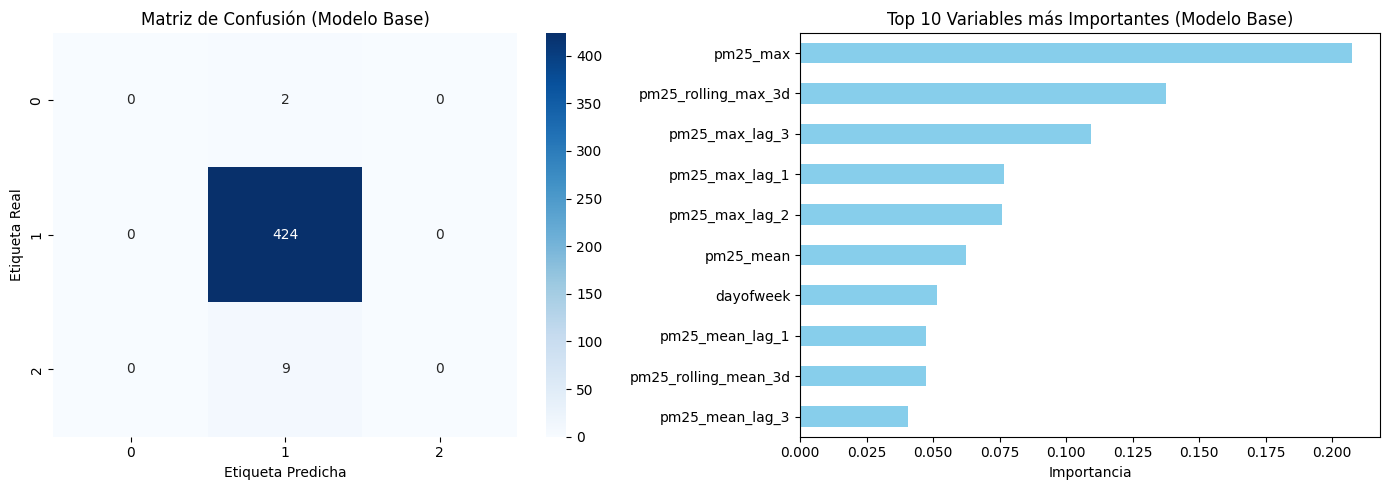

In [6]:
# ==============================================================================
# Celda 5: Evaluación inicial y visualizaciones del modelo base
# ==============================================================================
# Importancia de las Variables (Top 10) y matriz de confusión del modelo base
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Matriz de Confusión
sns.heatmap(confusion_matrix(y_test, y_pred_model), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Matriz de Confusión (Modelo Base)')
axes[0].set_xlabel('Etiqueta Predicha')
axes[0].set_ylabel('Etiqueta Real')

# Importancia de las Variables
importances = pd.Series(model.feature_importances_, index=features).sort_values(ascending=True)
importances.tail(10).plot(kind='barh', ax=axes[1], color='skyblue')
axes[1].set_title('Top 10 Variables más Importantes (Modelo Base)')
axes[1].set_xlabel('Importancia')

plt.tight_layout()
plt.show()

## Celda 6: Comparación de Algoritmos de Aprendizaje Automático Clásico
Para contrastar el rendimiento del modelo seleccionado, evaluamos y comparamos diferentes clasificadores tradicionales (Random Forest, Regresión Logística, Máquinas de Soporte Vectorial y k-NN) entrenados con balanceo de peso en sus clases.

In [7]:
# ==============================================================================
# Celda 6 (Nueva): Comparación de Algoritmos de Aprendizaje Automático Clásico (Classic ML)
# Evaluamos únicamente modelos permitidos en el plan de estudios (Trees, Logistic Regression, SVM, k-NN)
# ==============================================================================
models = {
    'Random Forest (Balanceado)': RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42),
    'Regresión Logística': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    'SVM (RBF Kernel)': SVC(class_weight='balanced', random_state=42),
    'k-NN (k=5)': KNeighborsClassifier(n_neighbors=5)
}

results = []

for name, clf in models.items():
    # Entrenamiento del modelo
    clf.fit(X_train, y_train)
    preds = clf.predict(X_test)

    # Cálculo de métricas claves
    acc = accuracy_score(y_test, preds)
    f1_macro = f1_score(y_test, preds, average='macro', zero_division=0)

    # Sensibilidad (Recall) para la clase crítica (Clase 2: Dañina)
    recall_danina = recall_score(y_test, preds, labels=[2], average='macro', zero_division=0)

    results.append({
        'Modelo': name,
        'Exactitud (Accuracy)': f"{acc * 100:.2f}%",
        'Puntuación F1 (Macro)': round(f1_macro, 4),
        'Sensibilidad Clase Dañina (Recall C2)': round(recall_danina, 4)
    })

# Conversión de los resultados a un DataFrame para fácil visualización
df_results = pd.DataFrame(results)
print("=== Resumen Comparativo de Modelos Clásicos ===")
display(df_results)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


=== Resumen Comparativo de Modelos Clásicos ===


,Modelo,Exactitud (Accuracy),Puntuación F1 (Macro),Sensibilidad Clase Dañina (Recall C2)
0,Random Forest (Balanceado),97.47%,0.3291,0.0000
1,Regresión Logística,90.11%,0.3873,0.3333
2,SVM (RBF Kernel),88.97%,0.3671,0.2222
3,k-NN (k=5),96.09%,0.3267,0.0000


## Celda 7: Optimización de Hiperparámetros y Evaluación del Modelo Final
En esta última sección de código, se realiza un ajuste fino del modelo **Random Forest** mediante una búsqueda en cuadrícula (`GridSearchCV`).

Para evitar el sobreajuste (overfitting) en datos de series de tiempo, se utiliza una técnica de **Validación Cruzada Temporal (`TimeSeriesSplit`)**. Finalmente, se entrena el modelo con los mejores hiperparámetros encontrados y se genera el reporte métrico detallado comparándolo con la línea base de persistencia para verificar la mejora en la capacidad predictiva.

In [8]:
# ==============================================================================
# Celda 7 (Consolidada): Optimización de Hiperparámetros y Reporte Comparativo Final
# ==============================================================================
# 1. Configuración de la validación cruzada respetando el orden temporal
tscv = TimeSeriesSplit(n_splits=5)

param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [5, 10, None],
    'min_samples_split': [2, 5]
}

# Búsqueda en cuadrícula con evaluación orientada al F1-Score Macro
grid_rf = GridSearchCV(
    estimator=RandomForestClassifier(class_weight='balanced', random_state=42),
    param_grid=param_grid,
    cv=tscv,
    scoring='f1_macro',
    n_jobs=-1
)

grid_rf.fit(X_train, y_train)

print("--- Mejores Hiperparámetros Encontrados ---")
print(grid_rf.best_params_)

# Modelo final optimizado
best_rf = grid_rf.best_estimator_
y_pred_best = best_rf.predict(X_test)

# 2. Resumen Métrico Consolidado y Comparación con la Línea Base
acc_base = accuracy_score(y_test, y_pred_baseline)
acc_model = accuracy_score(y_test, y_pred_best)
f1_model = f1_score(y_test, y_pred_best, average='weighted')

print("\n" + "="*60)
print("             RESUMEN DE EVALUACIÓN MÉTRICA FINAL             ")
print("="*60)
print(f"Exactitud de la Línea Base (Persistencia): {acc_base * 100:.2f}%")
print(f"Exactitud del Modelo Optimizado (Random Forest): {acc_model * 100:.2f}%")
print(f"Puntuación F1 Ponderada (Modelo Optimizado):   {f1_model:.4f}")
print("="*60)

print("\n--- Reporte de Clasificación Detallado del Modelo Optimizado ---")
print(classification_report(y_test, y_pred_best, zero_division=0))

--- Mejores Hiperparámetros Encontrados ---
{'max_depth': 5, 'min_samples_split': 2, 'n_estimators': 200}

             RESUMEN DE EVALUACIÓN MÉTRICA FINAL             
Exactitud de la Línea Base (Persistencia): 94.94%
Exactitud del Modelo Optimizado (Random Forest): 96.55%
Puntuación F1 Ponderada (Modelo Optimizado):   0.9624

--- Reporte de Clasificación Detallado del Modelo Optimizado ---
              precision    recall  f1-score   support

         0.0       0.00      0.00      0.00         2
         1.0       0.98      0.99      0.98       424
         2.0       0.25      0.22      0.24         9

    accuracy                           0.97       435
   macro avg       0.41      0.40      0.41       435
weighted avg       0.96      0.97      0.96       435



## Conclusiones y Resumen del Proyecto
Tras completar el análisis y optimización de los modelos, se destacan las siguientes conclusiones clave:

* **Rendimiento del Modelo**: El clasificador **Random Forest Optimizado** logró una exactitud del **96.55%** y una puntuación F1 ponderada de **0.9624**, superando consistentemente a la línea base de persistencia (94.94%).
* **Desbalance de Clases**: A pesar del alto rendimiento general, la clase crítica (Categoría Dañina / Clase 2) cuenta con pocos registros, lo que se refleja en una sensibilidad (Recall) más baja para esa clase específica. El uso de pesos balanceados (`class_weight='balanced'`) ayudó a mitigar este comportamiento.
* **Variables Clave**: Las variables de retraso temporal (lags) y los valores máximos de PM2.5 de los días anteriores resultaron ser los predictores con mayor impacto en la toma de decisiones del modelo.
* **Trabajo Futuro**: Se sugiere explorar técnicas avanzadas de sobremuestreo específicas para series temporales o la inclusión de variables meteorológicas adicionales para mejorar aún más la detección de días con alertas críticas de contaminación.